# Лабораторная работа № 1. Разведочный анализ больших данных
Студент: Жакупов М.С, группа ЭВМ 2.2
Датасет: US Accidents (2016–2023), https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents
## Часть 2. Разведочный анализ

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession, functions as F
from pyspark import StorageLevel

USER = os.getenv('USER')
WAREHOUSE = f'hdfs:///user/{USER}/zhakupov_directory/warehouse'
DB = 'zhakupov_database'
TABLE = f'spark_catalog.{DB}.us_accidents'
CLEAN_TABLE = f'spark_catalog.{DB}.us_accidents_clean'

spark = (SparkSession.builder
    .appName('zhakupov_lab1_eda')
    .master('yarn')
    .config('spark.submit.deployMode', 'client')
    .config('spark.executor.instances', '2')
    .config('spark.executor.cores', '2')
    .config('spark.executor.memory', '4g')
    .config('spark.driver.memory', '4g')
    .config('spark.sql.session.timeZone', 'UTC')
    .config('spark.jars.packages', 'org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0')
    .config('spark.sql.extensions', 'org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions')
    .config('spark.sql.catalog.spark_catalog', 'org.apache.iceberg.spark.SparkCatalog')
    .config('spark.sql.catalog.spark_catalog.type', 'hadoop')
    .config('spark.sql.catalog.spark_catalog.warehouse', WAREHOUSE)
    .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
sns.set_theme(style='whitegrid')

df = spark.table(TABLE).persist(StorageLevel.MEMORY_AND_DISK)
n_rows = df.count()
print('Строк:', f'{n_rows:,}', '| столбцов:', len(df.columns))

:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user5/.ivy2/cache
The jars for the packages stored in: /home/user5/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-49ae28a0-6897-48e7-a033-4347daea5565;1.0
	confs: [default]
	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 582ms :: artifacts dl 21ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spa

Строк: 7,728,394 | столбцов: 52


## Описание датасета
Датасет содержит записи о дорожно-транспортных происшествиях в 49 штатах США с февраля 2016 по март 2023 года.
Данные собраны из нескольких API потоковой информации о дорожных событиях (столбец `source`).
**Единица наблюдения:** одно ДТП. **Объём:** 7 728 394 записи, 46 исходных полей, CSV ≈ 3 ГБ.

| Группа | Поля | Тип признака |
|---|---|---|
| Идентификатор и источник | `id`, `source` | идентификатор; категориальный |
| Тяжесть | `severity` — влияние ДТП на движение, 1 (минимальное) … 4 (максимальное) | порядковый категориальный |
| Время | `start_time`, `end_time` — начало и конец влияния на движение, местное время | временной |
| Координаты | `start_lat`, `start_lng`, `end_lat`, `end_lng` | количественный, пространственный |
| Протяжённость | `distance_mi` — длина участка дороги, затронутого ДТП, мили | количественный, непрерывный |
| Описание | `description` — текстовое описание | текстовый |
| Адрес | `street`, `city`, `county`, `state`, `zipcode`, `country`, `timezone` | категориальный |
| Метеостанция | `airport_code` — ближайшая метеостанция, `weather_timestamp` — время наблюдения | категориальный; временной |
| Погода | `temperature_f`, `wind_chill_f` (°F), `humidity_pct` (%), `pressure_in` (дюймы рт. ст.), `visibility_mi` (мили), `wind_speed_mph` (миль/ч), `precipitation_in` (дюймы) | количественный, непрерывный |
| Погода (категории) | `wind_direction`, `weather_condition` | категориальный |
| Объекты рядом | `amenity`, `bump`, `crossing`, `give_way`, `junction`, `no_exit`, `railway`, `roundabout`, `station`, `stop`, `traffic_calming`, `traffic_signal`, `turning_loop` | бинарный |
| Время суток | `sunrise_sunset`, `civil_twilight`, `nautical_twilight`, `astronomical_twilight` — день или ночь по разным определениям сумерек | бинарный категориальный |
| Производные | `duration_min`, `start_date`, `start_year`, `start_month`, `start_dow` (1 = воскресенье), `start_hour` | количественный; временной |

### Пропущенные значения
Считаем долю пропусков (NULL и NaN) по каждому столбцу и проверяем, связаны ли они с источником данных и годом.

end_lat                  44.03
end_lng                  44.03
precipitation_in         28.51
wind_chill_f             25.87
wind_speed_mph            7.39
visibility_mi             2.29
wind_direction            2.27
humidity_pct              2.25
weather_condition         2.24
temperature_f             2.12
pressure_in               1.82
weather_timestamp         1.56
sunrise_sunset            0.30
civil_twilight            0.30
nautical_twilight         0.30
astronomical_twilight     0.30
airport_code              0.29
street                    0.14
timezone                  0.10
zipcode                   0.02
city                      0.00
description               0.00


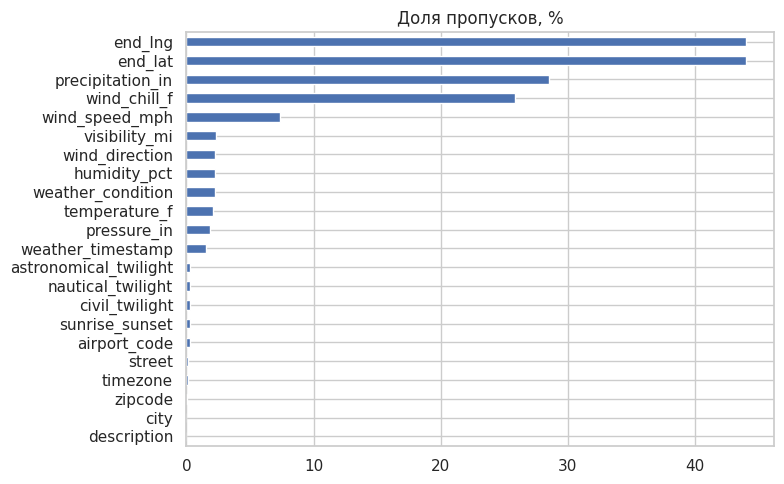

+-------+-------+----------------+------------+--------------+-----------------+
| source|end_lat|precipitation_in|wind_chill_f|wind_speed_mph|weather_timestamp|
+-------+-------+----------------+------------+--------------+-----------------+
|Source1|    0.0|            14.5|        12.4|           4.8|              1.8|
|Source2|  100.0|            47.0|        43.6|          10.8|              1.2|
|Source3|  100.0|            26.2|        22.0|           6.4|              1.4|
+-------+-------+----------------+------------+--------------+-----------------+



+----------+-------+----------------+------------+--------------+-----------------+
|start_year|end_lat|precipitation_in|wind_chill_f|wind_speed_mph|weather_timestamp|
+----------+-------+----------------+------------+--------------+-----------------+
|      2016|   68.5|            90.9|        90.0|          18.8|              0.8|
|      2017|   76.2|            88.0|        84.9|          18.8|              1.3|
|      2018|   81.2|            86.7|        81.2|          18.9|              1.4|
|      2019|   72.5|            23.0|        15.6|           6.3|              1.2|
|      2020|   39.9|             5.3|         3.4|           3.0|              2.0|
|      2021|   28.8|             4.2|         2.7|           2.4|              1.6|
|      2022|   13.4|             3.7|         3.1|           2.7|              1.7|
|      2023|    0.0|             4.5|         3.4|           3.2|              2.2|
+----------+-------+----------------+------------+--------------+-----------

In [5]:
float_cols = {c for c, t in df.dtypes if t == 'double'}
is_missing = {c: F.col(c).isNull() | F.isnan(c) if c in float_cols else F.col(c).isNull()
              for c in df.columns}

counts = df.agg(*[F.sum(e.cast('int')).alias(c) for c, e in is_missing.items()]).first().asDict()
missing = (pd.Series(counts)[lambda s: s > 0] / n_rows * 100).sort_values()
print(missing.sort_values(ascending=False).round(2).to_string())
missing.plot.barh(figsize=(8, 5), title='Доля пропусков, %')
plt.tight_layout(); plt.show()

# Доля пропусков (%) в разрезе источника и года
key = ['end_lat', 'precipitation_in', 'wind_chill_f', 'wind_speed_mph', 'weather_timestamp']
for group in ['source', 'start_year']:
    (df.groupBy(group)
       .agg(*[F.round(F.avg(is_missing[c].cast('int')) * 100, 1).alias(c) for c in key])
       .orderBy(group).show())

**Выводы.** Пропуски структурные: конечные координаты передаёт только `Source1` (у `Source2` и `Source3` — 100 % пропусков);
`precipitation_in` и `wind_chill_f` почти не записывались в 2016–2018 гг. (81–91 %), с 2020 г. — 3–5 %;
при отсутствии наблюдения метеостанции (120 228 записей) пропущены все погодные поля.
Ключевые поля (тяжесть, время, координаты начала, штат) заполнены полностью, поэтому строки не удаляем.

**Решения:**
- `end_lat`, `end_lng`, `wind_chill_f` — удалить: не восстанавливаются / являются производной величиной;
- `precipitation_in` — оставить NULL, анализировать только заполненные значения;
- температура, влажность, давление, видимость, скорость ветра — медиана того же штата и месяца, флаг `weather_imputed`;
- категориальные и адресные поля — значение `'Unknown'`.

In [4]:
from functools import reduce

num_fill = ['temperature_f', 'humidity_pct', 'pressure_in', 'visibility_mi', 'wind_speed_mph']
cat_fill = ['weather_condition', 'wind_direction', 'sunrise_sunset', 'civil_twilight',
            'nautical_twilight', 'astronomical_twilight', 'street', 'city', 'zipcode',
            'timezone', 'airport_code']

# Медианы по штату и месяцу (+ общая медиана на случай пустой группы)
medians = (df.groupBy('state', 'start_month')
             .agg(*[F.percentile_approx(c, 0.5).alias(c + '_med') for c in num_fill]))
global_med = df.agg(*[F.percentile_approx(c, 0.5).alias(c) for c in num_fill]).first().asDict()

filled = (df.drop('end_lat', 'end_lng', 'wind_chill_f')
            .withColumn('weather_imputed', reduce(lambda a, b: a | b,
                                                  [F.col(c).isNull() for c in num_fill]))
            .join(F.broadcast(medians), ['state', 'start_month'], 'left'))
for c in num_fill:
    filled = filled.withColumn(c, F.coalesce(F.col(c), F.col(c + '_med'), F.lit(global_med[c])))
filled = (filled.drop(*[c + '_med' for c in num_fill])
                .fillna('Unknown', subset=cat_fill)
                .persist(StorageLevel.MEMORY_AND_DISK))

print('Строк:', filled.count(), '| столбцов:', len(filled.columns))
df.unpersist()

left = filled.agg(*[F.sum(F.col(c).isNull().cast('int')).alias(c)
                    for c in filled.columns]).first().asDict()
print('Оставшиеся пропуски:', {k: v for k, v in left.items() if v})
print('Строк с восстановленной погодой:', filled.filter('weather_imputed').count())

Строк: 7728394 | столбцов: 50


Оставшиеся пропуски: {'description': 5, 'weather_timestamp': 120228, 'precipitation_in': 2203586}


Строк с восстановленной погодой: 632707


### Дубликаты
Проверяем уникальность `id` и наличие записей, совпадающих во всех полях, кроме `id`.

In [6]:
n_ids = filled.select('id').distinct().count()
print('Повторяющихся id:', n_rows - n_ids)

content_cols = [c for c in filled.columns if c not in ('id', 'weather_imputed')]
dups = (filled.groupBy(*content_cols)
              .agg(F.count('*').alias('n'), F.collect_list('id').alias('ids'))
              .filter('n > 1')
              .persist(StorageLevel.MEMORY_AND_DISK))
print('Групп совпадающих записей:', dups.count(),
      '| лишних копий:', dups.agg(F.sum(F.col('n') - 1)).first()[0])
dups.select('ids', 'start_time', 'state', 'city', 'severity', 'description').show(5, truncate=60)

Повторяющихся id: 0


Групп совпадающих записей: 112521 | лишних копий: 117725
+----------------------+-------------------+-----+----------+--------+------------------------------------------------------------+
|                   ids|         start_time|state|      city|severity|                                                 description|
+----------------------+-------------------+-----+----------+--------+------------------------------------------------------------+
|[A-6409207, A-6470955]|2021-01-11 04:11:00|   AL|Birmingham|       2|Incident on I-20 WB near I-59 Road closed. Take alternate...|
|[A-6902132, A-6628516]|2020-10-03 12:14:00|   AL|  Mc Calla|       2|          Incident on I-20 WB near MM 93 Drive with caution.|
|[A-6856532, A-6599033]|2020-11-29 21:16:00|   AL|    Loxley|       2|           Incident on I-10 WB near MM 44 Left lane blocked.|
|[A-5799014, A-6047048]|2021-11-21 09:14:05|   AL|     Brent|       2|Incident on AL-5 NB near MM 85 Road closed. Take alternat...|
|[A-6963157, A-6716

id уникальны; найдено 117 725 лишних копий (1,5 %) — записи, совпадающие во всех полях, кроме id. Это повторная регистрация одного события, копии удалены

In [7]:
before = filled.count()
filled_dedup = filled.dropDuplicates(content_cols).persist(StorageLevel.MEMORY_AND_DISK)
n_clean = filled_dedup.count()
filled.unpersist(); dups.unpersist()
filled = filled_dedup
print(f'До: {before:,} | после: {n_clean:,} | удалено: {before - n_clean:,}')

До: 7,728,394 | после: 7,610,669 | удалено: 117,725


### Описательные статистики и выбросы
Для числовых признаков рассчитываем среднее, стандартное отклонение, квартили и экстремумы,
а также границы IQR: [Q1 − 1,5·IQR; Q3 + 1,5·IQR]. Выход за границы IQR — повод для проверки, а не доказательство ошибки.

In [8]:
num = ['distance_mi', 'duration_min', 'temperature_f', 'humidity_pct',
       'pressure_in', 'visibility_mi', 'wind_speed_mph', 'precipitation_in']

filled.select(*num).summary('count', 'mean', 'stddev', 'min', '25%', '50%', '75%', 'max') \
      .toPandas().set_index('summary').T

q = filled.approxQuantile(num, [0.25, 0.75], 0.001)
bounds = {c: (q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)) for c, (q1, q3) in zip(num, q)}
outside = filled.agg(*[F.sum(((F.col(c) < lo) | (F.col(c) > hi)).cast('int')).alias(c)
                       for c, (lo, hi) in bounds.items()]).first().asDict()
iqr = pd.DataFrame({'lower': {c: b[0] for c, b in bounds.items()},
                    'upper': {c: b[1] for c, b in bounds.items()},
                    'outside_IQR': outside})
iqr['percent'] = iqr['outside_IQR'] / n_clean * 100
display(filled.select(*num).summary('count', 'mean', 'stddev', 'min', '25%', '50%', '75%', 'max')
              .toPandas().set_index('summary').T)
display(iqr.round(2))

summary,count,mean,stddev,min,25%,50%,75%,max
distance_mi,7610669,0.5574624607982356,1.7763656022787042,0.0,0.0,0.026,0.456,441.75
duration_min,7610669,403.8573265744893,12748.896931131443,1.2166666666666666,30.95,74.63333333333334,124.61666666666666,2812939.0
temperature_f,7610669,61.717805123307876,18.963325553144998,-89.0,49.0,64.0,76.0,207.0
humidity_pct,7610669,64.82470502921622,22.61406393894748,1.0,49.0,67.0,84.0,100.0
pressure_in,7610669,29.540392928663664,1.0065763779090213,0.0,29.38,29.86,30.03,58.63
visibility_mi,7610669,9.11262558258676,2.6602490422126652,0.0,10.0,10.0,10.0,140.0
wind_speed_mph,7610669,7.627439309211818,5.2323738819205685,0.0,5.0,7.0,10.0,1087.0
precipitation_in,5417848,0.008471441059254521,0.11110417983468374,0.0,0.0,0.0,0.0,36.47


,lower,upper,outside_IQR,percent
distance_mi,-0.68,1.13,959474,12.61
duration_min,-109.58,264.95,713953,9.38
temperature_f,8.50,116.50,49680,0.65
humidity_pct,-3.50,136.50,0,0.00
pressure_in,28.40,31.01,448402,5.89
visibility_mi,10.00,10.00,1457720,19.15
wind_speed_mph,-2.50,17.50,286319,3.76
precipitation_in,0.00,0.00,525316,6.90


**Выводы по выбросам.** IQR используется для диагностики: для `visibility_mi` и `precipitation_in` границы вырождаются (10–10 и 0–0),
для `pressure_in` за границы выходят реальные высокогорные станции. Решения принимаются по предметным границам:
- строка удаляется, если длительность влияния ДТП больше суток или протяжённость участка больше 100 миль — это ошибки регистрации события;
- погодное значение заменяется на NULL (строка сохраняется), если оно физически невозможно:
  температура вне −50…130 °F, давление вне 19…32 дюймов, скорость ветра больше 150 миль/ч, осадки больше 10 дюймов.

In [9]:
row_rules = {'duration_gt_1day': F.col('duration_min') > 1440,
             'distance_gt_100mi': F.col('distance_mi') > 100}
weather_limits = {'temperature_f': (-50, 130), 'pressure_in': (19, 32),
                  'wind_speed_mph': (0, 150), 'precipitation_in': (0, 10)}

# Сколько записей затрагивает каждое правило (правила могут пересекаться)
filled.agg(*[F.sum(cond.cast('int')).alias(name) for name, cond in row_rules.items()],
           *[F.sum((~F.col(c).between(lo, hi)).cast('int')).alias(c + '_invalid')
             for c, (lo, hi) in weather_limits.items()]).show(vertical=True)

clean = filled
for cond in row_rules.values():
    clean = clean.filter(~cond)
for c, (lo, hi) in weather_limits.items():
    clean = clean.withColumn(c, F.when(F.col(c).between(lo, hi), F.col(c)))
clean = clean.persist(StorageLevel.MEMORY_AND_DISK)

before, n_clean = n_clean, clean.count()
filled.unpersist()
print(f'До: {before:,} | после: {n_clean:,} | удалено: {before - n_clean:,} ({(before - n_clean) / before * 100:.2f}%)')
display(clean.select(*num).summary('count', 'mean', 'stddev', 'min', '25%', '50%', '75%', 'max')
             .toPandas().set_index('summary').T)

-RECORD 0-------------------------
 duration_gt_1day         | 32221 
 distance_gt_100mi        | 86    
 temperature_f_invalid    | 66    
 pressure_in_invalid      | 123   
 wind_speed_mph_invalid   | 51    
 precipitation_in_invalid | 60    



До: 7,610,669 | после: 7,578,362 | удалено: 32,307 (0.42%)


summary,count,mean,stddev,min,25%,50%,75%,max
distance_mi,7578362,0.5534112551080589,1.6877046801857931,0.0,0.0,0.025,0.453,99.952
duration_min,7578362,107.10539483554149,122.35067285637163,1.2166666666666666,30.633333333333333,74.5,124.0,1440.0
temperature_f,7578296,61.72754705015484,18.952727286590925,-50.0,49.0,64.0,76.0,129.2
humidity_pct,7578362,64.82683236826111,22.609482385965165,1.0,49.0,67.0,84.0,100.0
pressure_in,7578239,29.542961583819118,0.9982748972813283,19.21,29.38,29.86,30.03,31.15
visibility_mi,7578362,9.11267383109965,2.6611475907420408,0.0,10.0,10.0,10.0,140.0
wind_speed_mph,7578311,7.62470163866326,5.086972227217337,0.0,5.0,7.0,10.0,145.0
precipitation_in,5387029,0.008362017356877045,0.10253534798009223,0.0,0.0,0.0,0.0,10.0


### Категориальные признаки
Распределение ДТП по тяжести, времени суток, штатам и погодным условиям, а также доля ДТП рядом с объектами дорожной инфраструктуры.

,severity,count,percent
3,1,65561,0.87
0,2,6020138,79.44
1,3,1294874,17.09
2,4,197789,2.61


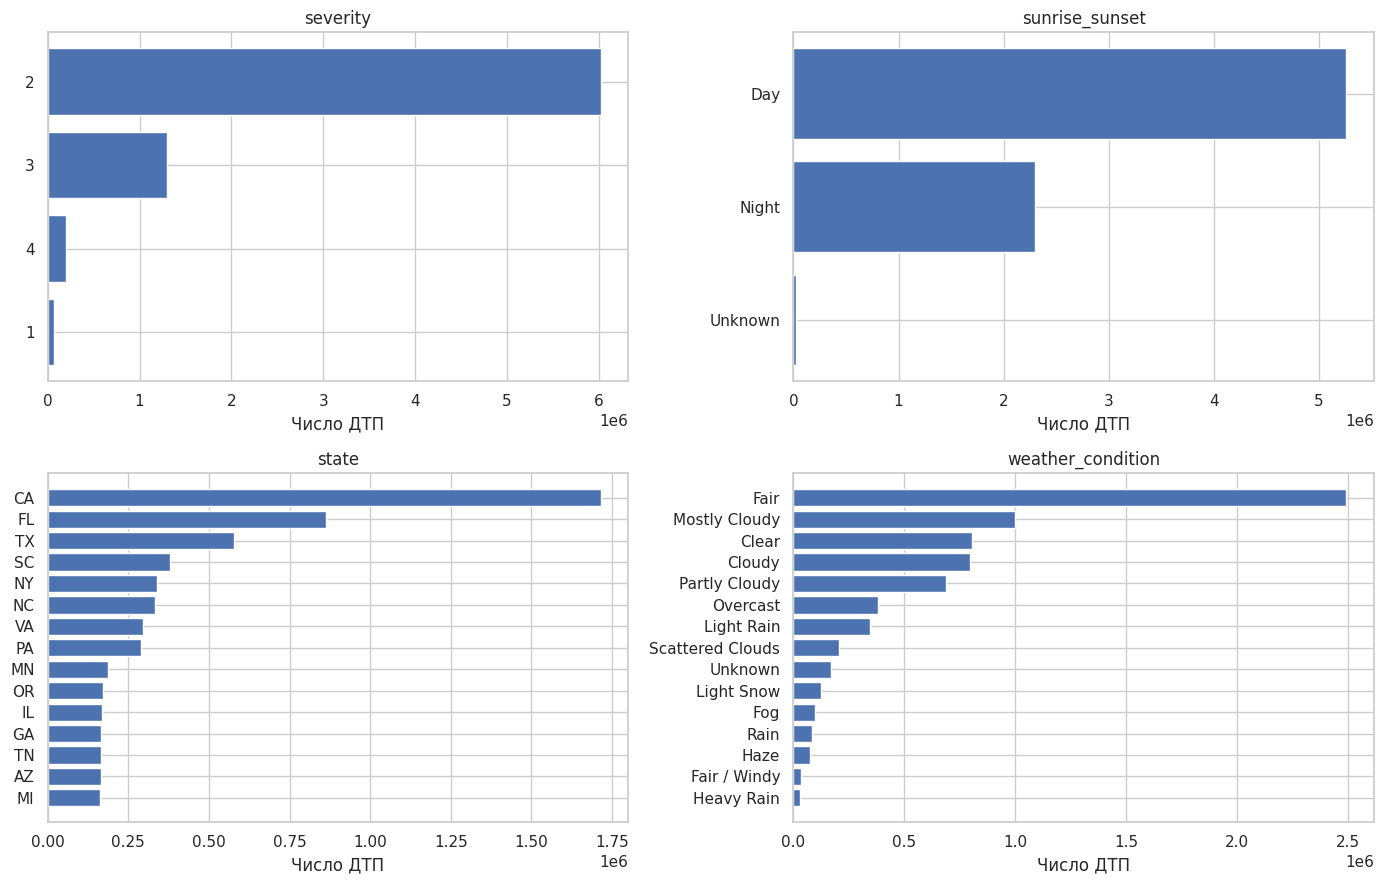

Доля ДТП рядом с объектом, %
traffic_signal     14.85
crossing           11.32
junction            7.37
stop                2.76
station             2.61
amenity             1.25
railway             0.87
give_way            0.47
no_exit             0.25
traffic_calming     0.10
bump                0.05
roundabout          0.00
turning_loop        0.00


In [10]:
def counts(col, n=15):
    return clean.groupBy(col).count().orderBy(F.desc('count')).limit(n).toPandas()

sev = counts('severity').sort_values('severity')
sev['percent'] = (sev['count'] / n_clean * 100).round(2)
display(sev)

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for a, col, n in [(ax[0, 0], 'severity', 4), (ax[0, 1], 'sunrise_sunset', 3),
                  (ax[1, 0], 'state', 15), (ax[1, 1], 'weather_condition', 15)]:
    t = counts(col, n).sort_values('count')
    a.barh(t[col].astype(str), t['count'])
    a.set_title(col)
    a.set_xlabel('Число ДТП')
plt.tight_layout()
plt.show()

bool_cols = ['amenity', 'bump', 'crossing', 'give_way', 'junction', 'no_exit', 'railway',
             'roundabout', 'station', 'stop', 'traffic_calming', 'traffic_signal', 'turning_loop']
poi = (clean.agg(*[F.avg(F.col(c).cast('int')).alias(c) for c in bool_cols])
            .toPandas().T[0].mul(100).sort_values(ascending=False))
print('Доля ДТП рядом с объектом, %')
print(poi.round(2).to_string())

**Выводы.** 79,4 % ДТП имеют тяжесть 2, тяжесть 1 и 4 — 0,9 % и 2,6 %: классы сильно несбалансированы.
Около 70 % ДТП происходят днём. Больше всего ДТП в CA, FL и TX.
В погодных условиях встречаются синонимы (`Fair` и `Clear`) — разные источники по-разному называют ясную погоду.
Чаще всего ДТП происходят у светофоров (14,9 %), пешеходных переходов (11,3 %) и развязок (7,4 %);
`turning_loop` практически не принимает значение True и неинформативен.

### Распределения числовых признаков
Графики строятся по случайной выборке (~60 тыс. строк, seed = 42); статистики выше рассчитаны по всем данным.
Гистограммы ограничены 99-м процентилем для читаемости — из данных при этом ничего не удаляется.

Размер выборки для графиков: 60045


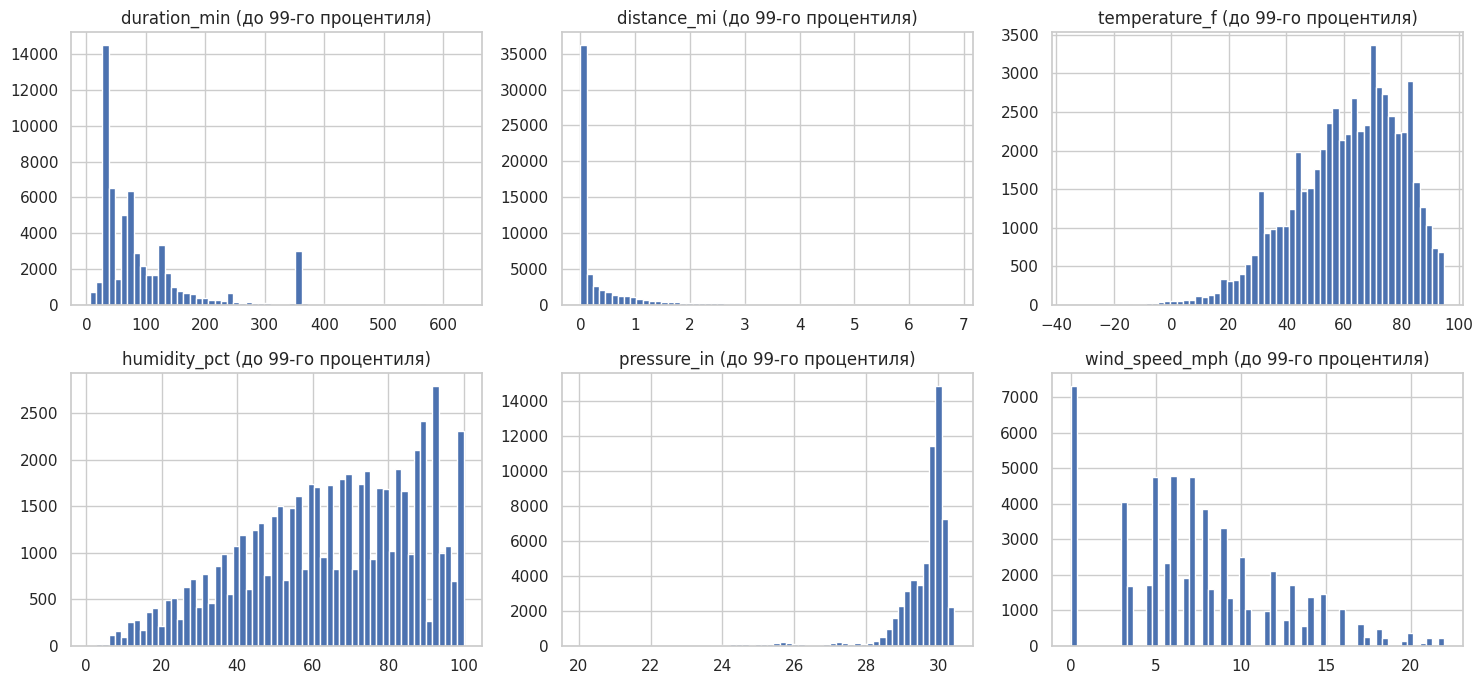

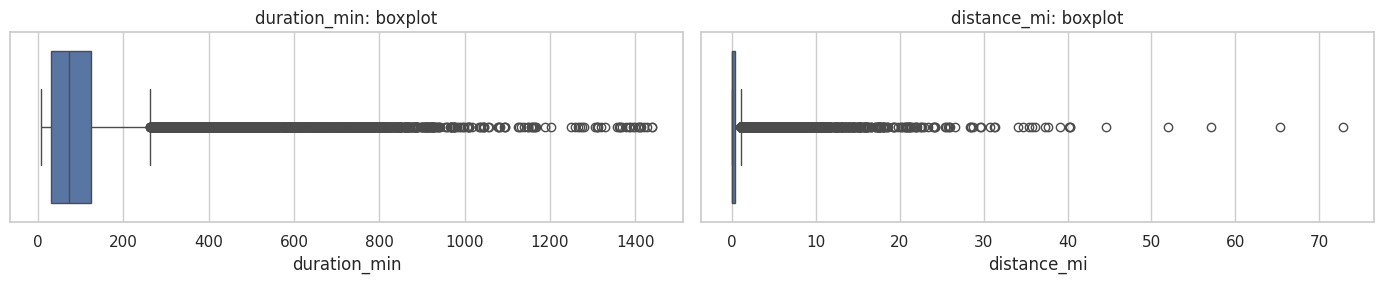

In [11]:
fraction = min(1.0, 60000 / n_clean)
sample = clean.select(*num).sample(False, fraction, seed=42).toPandas()
print('Размер выборки для графиков:', len(sample))

plot_cols = ['duration_min', 'distance_mi', 'temperature_f',
             'humidity_pct', 'pressure_in', 'wind_speed_mph']
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, c in zip(ax.flat, plot_cols):
    s = sample[c].dropna()
    s[s <= s.quantile(0.99)].hist(bins=60, ax=a)
    a.set_title(f'{c} (до 99-го процентиля)')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 3))
for a, c in zip(ax, ['duration_min', 'distance_mi']):
    sns.boxplot(x=sample[c], ax=a)
    a.set_title(f'{c}: boxplot')
plt.tight_layout(); plt.show()

**Выводы.** Длительность и протяжённость сильно скошены вправо: типичное ДТП затрагивает короткий участок (медиана 0,025 мили)
и влияет на движение около 75 минут. На гистограмме длительности видны пики на «круглых» значениях (30 мин, 6 ч) —
вероятно, часть источников подставляет стандартную длительность, поэтому этот признак частично условный.
Температура скошена влево (основная масса 50–85 °F), давление имеет длинный левый хвост — высокогорные станции.
Скорость ветра и температура дискретны из-за округления на метеостанциях; слабый ветер записывается как 0.

### Распределение ДТП во времени
Число ДТП по годам, месяцам, дням недели и часам. Время местное для штата.
2016 год представлен с февраля, 2023 — только январём–мартом, поэтому эти годы неполные.

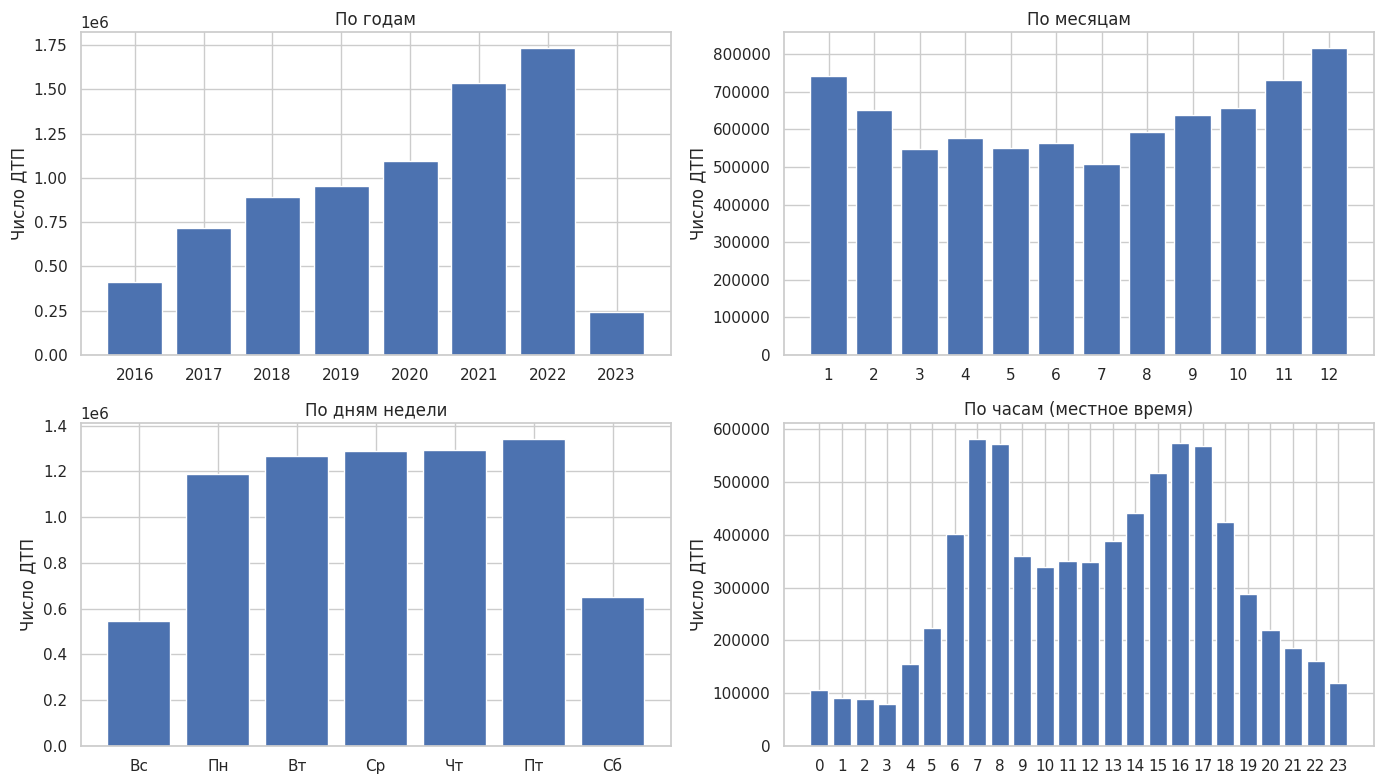

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
dow_names = ['Вс', 'Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб']
for a, col, title in [(ax[0, 0], 'start_year', 'По годам'), (ax[0, 1], 'start_month', 'По месяцам'),
                      (ax[1, 0], 'start_dow', 'По дням недели'), (ax[1, 1], 'start_hour', 'По часам (местное время)')]:
    t = clean.groupBy(col).count().orderBy(col).toPandas()
    labels = [dow_names[i - 1] for i in t[col]] if col == 'start_dow' else t[col].astype(str)
    a.bar(labels, t['count'])
    a.set_title(title); a.set_ylabel('Число ДТП')
plt.tight_layout(); plt.show()

**Выводы.** Число зарегистрированных ДТП растёт с 2016 по 2022 год, однако это может отражать расширение
покрытия источников данных, а не рост аварийности; 2016 и 2023 годы неполные. Больше всего ДТП в декабре–январе
и осенью, меньше всего летом. В будни ДТП примерно вдвое больше, чем в выходные. По часам выделяются два пика —
7–8 и 15–17 ч — что совпадает с часами пик и указывает на связь числа ДТП с интенсивностью движения.

### Корреляции и сохранение очищенных данных
Коэффициенты Пирсона рассчитываются средствами Spark MLlib по строкам без пропусков.
`precipitation_in` не включается: 29 % пропусков сократили бы выборку почти на треть.
`severity` — порядковый признак, поэтому коэффициент для него показывает лишь общую тенденцию.
Очищенная таблица сохраняется в Iceberg как отдельная таблица `us_accidents_clean`.

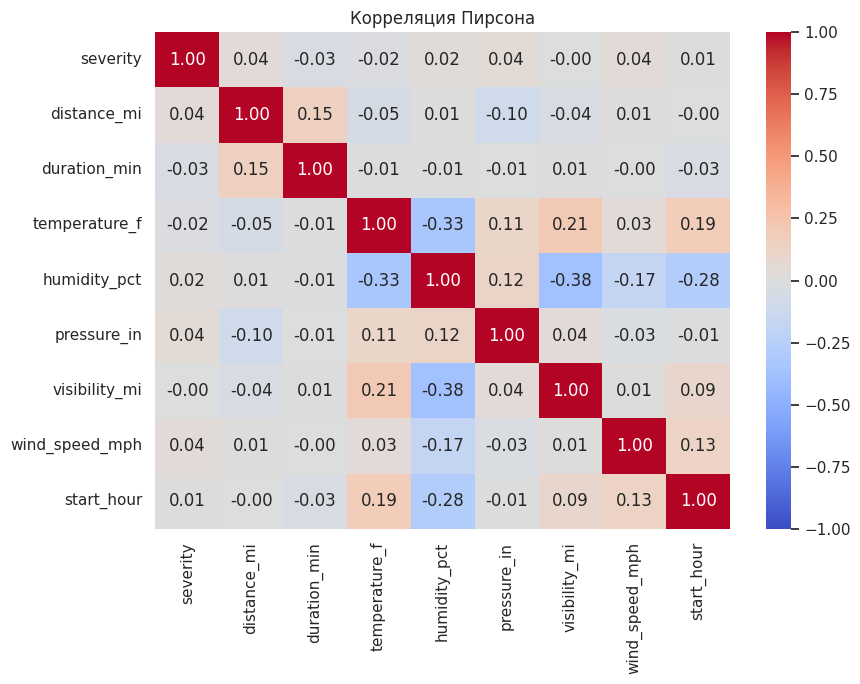

Сохранено: spark_catalog.zhakupov_database.us_accidents_clean | строк: 7578362


In [13]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

corr_cols = ['severity', 'distance_mi', 'duration_min', 'temperature_f', 'humidity_pct',
             'pressure_in', 'visibility_mi', 'wind_speed_mph', 'start_hour']
data = clean.select(*[F.col(c).cast('double') for c in corr_cols]).na.drop()
vec = VectorAssembler(inputCols=corr_cols, outputCol='features').transform(data)
m = Correlation.corr(vec, 'features', 'pearson').first()[0].toArray()
corr = pd.DataFrame(m, index=corr_cols, columns=corr_cols)

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Корреляция Пирсона'); plt.tight_layout(); plt.show()

clean.writeTo(CLEAN_TABLE).using('iceberg').createOrReplace()
print('Сохранено:', CLEAN_TABLE, '| строк:', spark.table(CLEAN_TABLE).count())

**Выводы.** Сильных линейных связей нет. Тяжесть ДТП практически не коррелирует с погодой, временем и длительностью (|r| ≤ 0,04).
Наиболее заметные связи — между погодными признаками и объясняются физикой: влажность и видимость (−0,38),
влажность и температура (−0,33). Связь часа с температурой (+0,19) и влажностью (−0,28) отражает суточный ход погоды.
Протяжённость и длительность связаны слабо (+0,15). Коэффициент Пирсона улавливает только линейные связи
и не доказывает причинности.

## Выводы
1. Исходный набор — 7 728 394 записи о ДТП в США (2016–2023), 46 полей, CSV ≈ 3 ГБ; данные загружены в HDFS
   и обработаны в Apache Spark на кластере под управлением YARN, результаты сохранены в Apache Iceberg.
2. Типы приведены без ошибок; время у 743 166 записей `Source1` хранилось в двух нестандартных форматах (с долями секунды) и было корректно разобрано.
3. Пропуски носят структурный характер и зависят от источника и периода. Конечные координаты и wind chill удалены,
   погодные показатели восстановлены медианой по штату и месяцу (632 707 записей, флаг `weather_imputed`),
   категориальные пропуски заменены на `Unknown`, осадки оставлены с пропусками.
4. Удалено 117 725 полных дубликатов (одно событие под разными `id`) и 32 307 записей с нереалистичной длительностью
   (> 1 сут.) или протяжённостью (> 100 миль); физически невозможные погодные значения заменены на NULL.
   Итог — 7 578 362 записи (исключено 1,94 %). IQR использован только для диагностики: для видимости и осадков его границы вырождаются.
5. 79,4 % ДТП имеют тяжесть 2; медиана длительности — 74,5 мин, протяжённости — 0,025 мили. Длительность частично условна (пики на 30 мин и 6 ч).
6. ДТП концентрируются в будни и в часы пик (7–8 и 15–17 ч), зимой их больше, чем летом; чаще всего — у светофоров, переходов и развязок.
7. Рост числа ДТП по годам может отражать расширение покрытия источников. Сильных корреляций нет: тяжесть ДТП не объясняется
   имеющимися числовыми признаками.

In [14]:
clean.unpersist()
spark.stop()